# Train the Confidence Head

This notebook trains the confidence head on a built cache and scores it on the report split. It is for the team members who run the training and read its results. [`cache-tutorial.ipynb`](cache-tutorial.ipynb) explains the arrays of the cache; this notebook uses its terms without explaining them again.

### What Is Trained

Depth Anything V2 (DA2) gives every pixel a depth. The confidence head learns where that depth is wrong. For every cell of the cache grid, it outputs `p_error`: the probability that the DA2 depth in the cell is off by more than `tau` = 10%. The error is the AbsRel, |predicted - z| / z, against the lidar depth z.

DA2 is frozen and does not run here: the cache holds its outputs, computed once. The head is the only network that trains. It has 4 convolution layers and about 95,000 weights (section 4).

| | Per camera image |
|---|---|
| input `x` | 68 channels per cell: 64 DA2 decoder features, the DA2 depth, the temporal spread, the radar residual, the radar validity |
| output | 1 logit per cell; `p_error` = sigmoid(logit) |
| `target` | 1 where the AbsRel of the cell is above `tau`, else 0 |
| `mask` | 1 where a lidar point lands in the cell; only these cells count in the loss and the scores |

The head learns from scattered cells but predicts every cell, so at inference it needs no lidar. The inputs come from the camera and the radar, which a deployed car has. One input depends on lidar: the build used the lidar fit to give the keyframe its metric scale when it computed the temporal spread (`temporal.align = "lidar"` in the cache settings).

### How It Trains

| Part | Choice |
|---|---|
| loss | binary cross-entropy over the labeled cells, with the positive cells weighted by negatives / positives |
| optimizer | AdamW, learning rate 1e-3, weight decay 1e-4, cosine decay to 0 over all steps |
| batches | 8 images per batch, 8 epochs |
| checkpoint | the epoch with the lowest AUSE on dev |
| scores | AUSE and AURG per image, averaged over images; AUROC over the labeled cells |
| baseline | the raw temporal spread, scored the same way |

The loss, the optimizer, the batches, and the checkpoint rule come from the Run 1 plan ([`Docs/Wiki/CS566 Confidence Head Training Run 1.md`](../../Docs/Wiki/CS566%20Confidence%20Head%20Training%20Run%201.md)). AUSE, AURG, and the temporal baseline come from the pre-proposal. AUROC is added here, because it scores the task that the loss trains. The inputs follow the cache, which departs from the Run 1 plan in several ways ([`Docs/Wiki/CS566 Implementation Deviations and Open Questions.md`](../../Docs/Wiki/CS566%20Implementation%20Deviations%20and%20Open%20Questions.md)); for example, `x` holds the temporal spread, which Run 1 left for Run 2.

The splits follow the dataset strategy ([`Docs/Wiki/CS566 Dataset Strategy.md`](../../Docs/Wiki/CS566%20Dataset%20Strategy.md)). Each split holds whole scenes, because the images of one scene are correlated:

| Split | Scenes | Use |
|---|---|---|
| train | the official train scenes that are not in dev | fit the head |
| dev | 10% of the official train scenes, drawn per condition and weather | choose the checkpoint |
| val | the official val scenes | the reported scores, computed once at the end |

No choice in this notebook uses val, so the val scores measure the head on scenes that took no part in training or in the choice of checkpoint.

> **Note.** The outputs saved in this notebook come from the v1.0-mini cache at the 132 x 74 grid: 6 train scenes, 2 dev scenes, and 2 val scenes, both val scenes by day and clear. They show that the code runs end to end. They say little about how well the head works.

## Setup

This section imports the packages and finds the confhead folder. `confhead.head` holds the head and its loss, and `confhead.metrics` holds the scores. Both are in the library, so a training job on CARC can use the same code as this notebook.

In [1]:
import json
import multiprocessing as mp
import os
import subprocess
import time
from collections import defaultdict
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, RandomSampler, Subset

from confhead import Cache, ConfidenceDataset, ConfidenceHead, HeadInputs, load_config
from confhead.head import masked_bce
from confhead.metrics import auroc, ause_aurg, sparsification
from confhead.plot import draw_map

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

# The confhead folder: the nearest parent that holds configs/ and pyproject.toml.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir() and (p / "pyproject.toml").is_file())


def table(headers, rows):
    """Rows as a markdown table."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    return Markdown("\n".join(lines))


def git_commit():
    """The commit of the repository, with -dirty when tracked files have changed."""
    run = lambda *args: subprocess.run(["git", *args], cwd=PROJECT, capture_output=True, text=True).stdout.strip()
    return run("rev-parse", "--short", "HEAD") + ("-dirty" if run("status", "--porcelain", "--untracked-files=no") else "")

## 1. Settings

**Settings to change:** every setting of a run is in the cell below. The training defaults come from the Run 1 plan, and the split defaults from the dataset strategy. A run writes its settings, its checkpoints, and its scores to `RUN_DIR`; section 12 lists the files.

| Setting | Default | Effect |
|---|---|---|
| `CACHE_ROOT` | `None` | The cache to train on. `None` takes the first cache that exists: your trainval cache on CARC, then the mini caches under `outputs/`. |
| `DATAROOT` | `None` | Where the nuScenes images are, for the figures of section 10. `None`: the folder the cache was built from. |
| `RUN_NAME` | `None` | The folder of the run. `None` names it after the cache and the time. To continue a run that stopped, set it to the name of that folder. |
| `RUNS` | `None` | The folder of all runs. `None`: `/scratch1/$USER/confhead-runs` on CARC, `outputs/runs` elsewhere. |
| `INPUTS` | `HeadInputs()` | The channel groups of `x`, `tau`, and the radar settings. Change it for an ablation. |
| `WIDTHS` | `(64, 64, 32)` | The channels of the three 3x3 convolutions |
| `EPOCHS`, `BATCH_SIZE` | 8, 8 | Passes over train, and images per step |
| `LR`, `WEIGHT_DECAY` | 1e-3, 1e-4 | AdamW |
| `SAMPLES_PER_EPOCH` | `None` | Train images per epoch, drawn at random. `None`: all of them. Section 5 says when to lower it. |
| `DEV_FRACTION` | 0.1 | The share of the official train scenes that go to dev |
| `DEV_LIMIT` | 3000 | Dev images scored after each epoch, a fixed random subset. `None`: all of them. |
| `STATS_SAMPLE` | 256 | Train images for the input statistics and the class weight |
| `CELLS_PER_IMAGE` | 500 | Labeled cells per image, drawn at random, for AUROC |
| `SEED` | 0 | The seed of the splits, the samples, the initial weights, and the batch order |
| `NUM_WORKERS` | `None` | Loader processes. `None`: one less than the CPUs of the session, at most 8. |

In [2]:
CACHE_ROOT = None
DATAROOT = None
RUN_NAME = None
RUNS = None

INPUTS = HeadInputs()
WIDTHS = (64, 64, 32)
EPOCHS = 8
BATCH_SIZE = 8
LR = 1e-3
WEIGHT_DECAY = 1e-4
SAMPLES_PER_EPOCH = None
DEV_FRACTION = 0.1
DEV_LIMIT = 3000
STATS_SAMPLE = 256
CELLS_PER_IMAGE = 500
SEED = 0
NUM_WORKERS = None

In [3]:
if CACHE_ROOT is None:
    candidates = [load_config(PROJECT / "configs/nuscenes-trainval.toml").output.root,
                  PROJECT / "outputs/cache/nuscenes-mini-g2", PROJECT / "outputs/cache/nuscenes-mini"]
    CACHE_ROOT = next((c for c in candidates if (Path(c) / "index.json").is_file()), None)
    if CACHE_ROOT is None:
        raise FileNotFoundError("no cache found; set CACHE_ROOT, or build one with examples/build_cache.py")
cache = Cache(CACHE_ROOT, DATAROOT)

if RUNS is None:
    scratch = Path("/scratch1") / os.environ.get("USER", "")
    RUNS = scratch / "confhead-runs" if scratch.is_dir() else PROJECT / "outputs/runs"
RUN_NAME = RUN_NAME or f"{cache.root.name}-{time.strftime('%Y%m%d-%H%M')}"
RUN_DIR = Path(RUNS) / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
if NUM_WORKERS is None:
    cpus = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
    NUM_WORKERS = max(0, min(8, cpus - 1))
# With spawn, the default on macOS, each loader process takes 5 s to stop; forkserver stops at once.
context = "forkserver" if NUM_WORKERS and mp.get_start_method() == "spawn" and "forkserver" in mp.get_all_start_methods() else None
loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda", multiprocessing_context=context)
torch.manual_seed(SEED)

grid = cache.settings["grid"]
print(f"cache    {cache.root}: {len(cache)} entries, fingerprint {cache.header['fingerprint']}")
print(f"run      {RUN_DIR}")
print(f"device   {device}" + (f" ({torch.cuda.get_device_name()})" if device.type == "cuda" else "") + f", {NUM_WORKERS} loader processes")

cache    /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/cache/nuscenes-mini-g2: 2424 entries, fingerprint e43e53bcb50cb85f
run      /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/runs/nuscenes-mini-g2-20261027-2331
device   mps, 8 loader processes


## 2. The Splits

`ConfidenceDataset(cache, INPUTS, tag=...)` gives the images of one split of the cache, as in section 8 of the tutorial. The cache knows the official splits, train and val. `dev_scenes` draws dev from the official train scenes. It groups the scenes by condition and weather, and takes `DEV_FRACTION` of each group, at least one scene from a group of 2 or more. So dev holds night and rain scenes whenever train has them. `Subset` then divides the official train set into train and dev.

`DEV_LIMIT` keeps the scoring after each epoch short: dev is scored on a fixed random subset of its images. Every epoch scores the same subset, so the scores of two epochs compare directly.

In [4]:
def dev_scenes(rows, fraction, seed):
    """A share of the scenes of each (condition, weather) group; at least one from a group of 2 or more."""
    groups = defaultdict(set)
    for r in rows:
        groups[(r["condition"], r["weather"])].add(r["scene"])
    rng = np.random.default_rng(seed)
    dev = []
    for _, scenes in sorted(groups.items()):
        n = max(1, round(len(scenes) * fraction)) if len(scenes) >= 2 else 0
        dev += rng.choice(sorted(scenes), size=n, replace=False).tolist()
    return sorted(dev)


official_train = ConfidenceDataset(cache, INPUTS, tag="train")
val_set = ConfidenceDataset(cache, INPUTS, tag="val")
names = official_train.channel_names
C = len(names)

dev = set(dev_scenes(official_train.rows, DEV_FRACTION, SEED))
train_idx = [i for i, r in enumerate(official_train.rows) if r["scene"] not in dev]
dev_all = [i for i, r in enumerate(official_train.rows) if r["scene"] in dev]
dev_idx = dev_all
if DEV_LIMIT and len(dev_all) > DEV_LIMIT:
    dev_idx = sorted(np.random.default_rng(SEED).choice(dev_all, DEV_LIMIT, replace=False).tolist())
train_set, dev_set = Subset(official_train, train_idx), Subset(official_train, dev_idx)


def describe(name, rows, scored):
    scenes = lambda **f: len({r["scene"] for r in rows if all(r[k] == v for k, v in f.items())})
    return name, scenes(), len(rows), scored, scenes(condition="night"), scenes(weather="rain")


display(table(["split", "scenes", "images", "images used", "night scenes", "rain scenes"], [
    describe("train", [official_train.rows[i] for i in train_idx], len(train_idx)),
    describe("dev", [official_train.rows[i] for i in dev_all], len(dev_idx)),
    describe("val", val_set.rows, len(val_set)),
]))
print(f"dev scenes: {', '.join(sorted(dev))}")

| split | scenes | images | images used | night scenes | rain scenes |
|---|---|---|---|---|---|
| train | 6 | 1458 | 1458 | 2 | 1 |
| dev | 2 | 480 | 480 | 1 | 0 |
| val | 2 | 486 | 486 | 0 | 0 |

dev scenes: scene-0796, scene-1100


The night and rain columns count scenes, not images. The images of one scene share their light, their weather, and most of their content, so a score per condition rests on the number of scenes. The dataset strategy treats a condition with fewer than 10 val scenes as indicative only.

## 3. Input Statistics and the Class Weight

The channels of `x` have different scales: the features are raw decoder activations, the depth is the disparity over its image mean, and the radar validity is 0 or 1. The head standardizes each channel with its mean and std over a sample of train images, so each channel reaches the first convolution with mean 0 and std 1. The statistics go into buffers of the head, so every checkpoint carries them.

The same pass counts the labels. `positive_rate` is the share of labeled cells with an AbsRel above `tau`. With fewer positive cells than negative ones, an unweighted loss favors predicting 0 everywhere. The class weight `POS_WEIGHT` = (1 - positive_rate) / positive_rate gives the two classes the same total weight in the loss. The Run 1 plan also sets a gate on the labels: a positive rate below 0.05 or above 0.70 means that the depth needs a scale per camera before training.

In [5]:
stats_idx = np.random.default_rng(SEED).choice(len(train_set), min(STATS_SAMPLE, len(train_set)), replace=False)
stats_loader = DataLoader(Subset(train_set, stats_idx.tolist()), **loader_args)

total, total_sq = torch.zeros(C, dtype=torch.float64), torch.zeros(C, dtype=torch.float64)
cells = labeled = positive = 0
t0 = time.perf_counter()
for batch in stats_loader:
    x = batch["x"].double()
    total += x.sum((0, 2, 3))
    total_sq += (x ** 2).sum((0, 2, 3))
    cells += x.shape[0] * x.shape[2] * x.shape[3]
    labeled += batch["mask"].sum().item()
    positive += (batch["target"] * batch["mask"]).sum().item()
mean = total / cells
std = (total_sq / cells - mean ** 2).clamp(min=0).sqrt()
positive_rate = positive / labeled
POS_WEIGHT = (1 - positive_rate) / positive_rate

feat = [i for i, n in enumerate(names) if n.startswith("feature_")]
rows = [(n, f"{mean[i]:.3f}", f"{std[i]:.3f}") for i, n in enumerate(names) if i not in feat]
if feat:
    rows.insert(0, (f"feature_0 to feature_{len(feat) - 1}", f"{mean[feat].min():.2f} to {mean[feat].max():.2f}",
                    f"{std[feat].min():.2f} to {std[feat].max():.2f}"))
display(table(["channel", "mean", "std"], rows))
print(f"{len(stats_idx)} train images in {time.perf_counter() - t0:.1f} s; {labeled / cells:.1%} of cells labeled")
print(f"positive_rate {positive_rate:.1%} (AbsRel > {INPUTS.labels.tau}); "
      f"gate 5% to 70%: {'inside' if 0.05 <= positive_rate <= 0.70 else 'OUTSIDE, see the Run 1 plan'}")
print(f"POS_WEIGHT {POS_WEIGHT:.3f}")

| channel | mean | std |
|---|---|---|
| feature_0 to feature_63 | -17.60 to 45.84 | 0.86 to 40.43 |
| depth | 1.000 | 0.886 |
| temporal_relstd | 0.052 | 0.121 |
| radar_residual | 0.013 | 0.089 |
| radar_valid | 0.034 | 0.182 |

256 train images in 3.3 s; 25.7% of cells labeled
positive_rate 37.2% (AbsRel > 0.1); gate 5% to 70%: inside
POS_WEIGHT 1.686


## 4. The Head

`ConfidenceHead` is the network of the Run 1 plan. It standardizes `x` with the statistics of section 3, applies three 3x3 convolutions with a ReLU after each, and ends with a 1x1 convolution to one logit per cell. The output has the size of the grid, so each logit lines up with one label.

Three 3x3 convolutions see 7 x 7 cells around each cell; the cell below converts that window to pixels. The window is small, but the decoder features already carry context from the whole image, because the DA2 encoder is a vision transformer. `WIDTHS` changes the number and the width of the 3x3 layers.

In [6]:
head = ConfidenceHead(C, WIDTHS).to(device)
head.set_input_stats(mean.float(), std.float())
print(head)

gw, gh = cache.entry(official_train.rows[0]).meta["grid_size"]
image_w = cache.entry(official_train.rows[0]).meta["image"]["width"]
window = 1 + 2 * len(WIDTHS)
print(f"{sum(p.numel() for p in head.parameters()):,} weights; input {C} x {gh} x {gw}, output 1 x {gh} x {gw}")
print(f"each logit sees {window} x {window} cells, about {window * image_w / gw:.0f} px of a {image_w} px wide image")

ConfidenceHead(
  (net): Sequential(
    (0): Conv2d(68, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
  )
)
94,657 weights; input 68 x 74 x 132, output 1 x 74 x 132
each logit sees 7 x 7 cells, about 85 px of a 1600 px wide image


## 5. Loading Speed

Each step of an epoch reads one `.npz` per image from disk, and computes the labels and the radar channels on the CPU. On the trainval cache at the default grid, an image is about 5.4 MB, so one epoch over the train images reads about 800 GB. The head itself is small. The cell below measures the loading and the training step apart, and estimates the time of one epoch from the slower of the two. The loading rate includes the start of the loader processes, so it errs low.

The Run 1 plan sets a limit: if an epoch takes more than 2 hours, train each epoch on a random half of the train images, with `SAMPLES_PER_EPOCH = len(train_set) // 2` in section 1. Each epoch then draws another half.

In [7]:
generator = torch.Generator()
sampler = RandomSampler(train_set, num_samples=SAMPLES_PER_EPOCH or len(train_set), generator=generator)
train_loader = DataLoader(train_set, sampler=sampler, drop_last=True, persistent_workers=NUM_WORKERS > 0, **loader_args)
dev_loader = DataLoader(dev_set, **loader_args)
val_loader = DataLoader(val_set, **loader_args)

probe = DataLoader(train_set, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_args)
n_batches = min(100, len(probe))
t0 = time.perf_counter()
for i, batch in enumerate(probe, 1):
    if i == n_batches:
        break
load_rate = n_batches * BATCH_SIZE / (time.perf_counter() - t0)

trial = ConfidenceHead(C, WIDTHS).to(device)
trial_opt = torch.optim.AdamW(trial.parameters())
x, target, mask = (batch[k].to(device) for k in ("x", "target", "mask"))
for i in range(21):
    if i == 1:
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
    trial_opt.zero_grad()
    loss = masked_bce(trial(x), target, mask, POS_WEIGHT)
    loss.backward()
    trial_opt.step()
    loss.item()  # waits for the device
step_rate = 20 * BATCH_SIZE / (time.perf_counter() - t0)
del trial, trial_opt

per_epoch = len(sampler)
minutes = per_epoch / min(load_rate, step_rate) / 60
total = EPOCHS * minutes
print(f"loading {load_rate:.0f} images/s with {NUM_WORKERS} processes; training step {step_rate:.0f} images/s on {device}")
print(f"one epoch of {per_epoch} images: about {minutes:.1f} min; {EPOCHS} epochs: about "
      + (f"{total:.0f} min" if total < 120 else f"{total / 60:.1f} h"))
if minutes > 120:
    print("over 2 hours per epoch: set SAMPLES_PER_EPOCH = len(train_set) // 2 in section 1, and run again from there")

loading 238 images/s with 8 processes; training step 705 images/s on mps
one epoch of 1458 images: about 0.1 min; 8 epochs: about 1 min


## 6. The Scores

The scores use the labeled cells of each image, with the AbsRel there as the error.

**Sparsification.** Sort the labeled cells of one image by `p_error`. Remove the most uncertain 2%, then 4%, and so on up to 98%, and each time take the mean AbsRel of the cells that remain. A good confidence map removes the wrong cells first, so the curve falls. The oracle removes the cells in the order of their true AbsRel, the best that any ranking can do. Random removal keeps the mean AbsRel, a flat line. Two areas summarize the curve:

- **AUSE**, the area between the curve and the oracle curve. 0 is a perfect ranking; lower is better.
- **AURG**, the area between random removal and the curve. Above 0 means the ranking beats chance; higher is better.

Both are in AbsRel units, computed per image and averaged over the images, as in Poggi et al., "On the uncertainty of self-supervised monocular depth estimation" (CVPR 2020). The oracle has an AUSE of 0 and random removal an AURG of 0, so the tables leave them out.

**AUROC** scores the task that the head trains on: how well `p_error` separates the cells above `tau` from the cells below it. It is the chance that a random positive cell gets a higher `p_error` than a random negative cell, where 0.5 is chance and 1 is perfect. AUROC pools the cells of all images, from a random sample of `CELLS_PER_IMAGE` labeled cells per image.

**The baseline** ranks the cells by their raw temporal spread, one of the baselines of the pre-proposal. The head has the spread as one of its inputs. If it does not beat the spread alone, it has learned nothing from the features and the radar that the spread does not already show.

`evaluate` runs the head over a loader and returns one row per image, the mean sparsification curves, and the masked loss. It skips the images with fewer than 20 labeled cells, such as the night images without a lidar fit. `summarize` turns a list of rows into the scores of the group.

In [8]:
T = names.index("temporal_relstd") if "temporal_relstd" in names else None
MIN_CELLS = 20
by_key = {r["key"]: r for r in cache.rows()}


@torch.no_grad()
def evaluate(head, loader, seed=SEED):
    """Score the head, and the temporal spread when x has it, on every image of a loader."""
    head.eval()
    rng = np.random.default_rng(seed)
    images, curves = [], defaultdict(float)
    loss_sum = labeled_sum = 0.0
    for batch in loader:
        logits = head(batch["x"].to(device, non_blocking=True))
        target, mask = batch["target"].to(device), batch["mask"].to(device)
        n = mask.sum().item()
        loss_sum += masked_bce(logits, target, mask, POS_WEIGHT).item() * n
        labeled_sum += n
        p_error = torch.sigmoid(logits)[:, 0].cpu().numpy()
        for i, key in enumerate(batch["key"]):
            m = batch["mask"][i, 0].numpy() > 0
            if m.sum() < MIN_CELLS:
                continue
            errors = batch["abs_rel"][i, 0].numpy()[m]
            labels = batch["target"][i, 0].numpy()[m] > 0
            scores = {"head": p_error[i][m]}
            if T is not None:
                scores["temporal"] = batch["x"][i, T].numpy()[m]
            r = by_key[key]
            row = {"key": key, "scene": r["scene"], "channel": r["channel"], "condition": r["condition"],
                   "weather": r["weather"], "cells": int(m.sum()), "positive": float(labels.mean()),
                   "mean_abs_rel": float(errors.mean())}
            for name, s in scores.items():
                row[f"ause_{name}"], row[f"aurg_{name}"] = ause_aurg(errors, s)
                curves[name] = curves[name] + sparsification(errors, s)
            curves["oracle"] = curves["oracle"] + sparsification(errors, errors)
            keep = rng.choice(len(errors), min(CELLS_PER_IMAGE, len(errors)), replace=False)
            row["sample"] = {"target": labels[keep], **{name: s[keep].astype(np.float32) for name, s in scores.items()}}
            images.append(row)
    return {"loss": loss_sum / max(labeled_sum, 1), "images": images,
            "curves": {k: v / max(len(images), 1) for k, v in curves.items()}}


def summarize(images):
    """The scores of a group of image rows from evaluate."""
    cells = sum(im["cells"] for im in images)
    s = {"scenes": len({im["scene"] for im in images}), "images": len(images), "cells": cells,
         "positive": sum(im["positive"] * im["cells"] for im in images) / cells}
    target = np.concatenate([im["sample"]["target"] for im in images])
    for name in ("head", "temporal"):
        if f"ause_{name}" in images[0]:
            s[f"auroc_{name}"] = auroc(np.concatenate([im["sample"][name] for im in images]), target)
            s[f"ause_{name}"] = float(np.mean([im[f"ause_{name}"] for im in images]))
            s[f"aurg_{name}"] = float(np.mean([im[f"aurg_{name}"] for im in images]))
    return s

## 7. Train

Each step loads a batch, computes the masked loss of section 3, and updates the head. The learning rate follows a cosine from `LR` down to 0 over all the steps of all epochs. After each epoch, the cell scores the head on dev and saves two checkpoints in `RUN_DIR`:

- `last.pt` after every epoch, with the optimizer and the schedule, to continue the run
- `best.pt` when the dev AUSE is the lowest so far

If `RUN_DIR` already holds `last.pt`, the next cell loads it, and training continues after its last epoch. So a session that ends loses at most one epoch: start a new session, set `RUN_NAME` to the run folder, and run every cell again. The batch order of an epoch depends only on `SEED` and the epoch number, so a continued run sees the same batches as one that never stopped.

The next cell also writes `config.json`: every setting, the dev scenes, the class weight, the cache fingerprint, and the git commit.

In [9]:
optimizer = torch.optim.AdamW(head.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))
history = []

last = RUN_DIR / "last.pt"
if last.is_file():
    state = torch.load(last, map_location=device)
    head.load_state_dict(state["head"])
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    history, POS_WEIGHT = state["history"], state["pos_weight"]
    print(f"continuing {RUN_DIR.name} after epoch {len(history)} of {EPOCHS}")
best_ause = min((h["dev_ause_head"] for h in history), default=float("inf"))

config = {
    "cache": str(cache.root), "fingerprint": cache.header["fingerprint"], "grid": [gw, gh],
    "inputs": asdict(INPUTS), "channels": names, "widths": list(WIDTHS),
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "weight_decay": WEIGHT_DECAY,
    "samples_per_epoch": len(sampler), "steps_per_epoch": len(train_loader),
    "positive_rate": positive_rate, "pos_weight": POS_WEIGHT, "stats_sample": len(stats_idx),
    "dev_fraction": DEV_FRACTION, "dev_scenes": sorted(dev), "dev_scored": len(dev_idx), "seed": SEED,
    "git": git_commit(), "torch": torch.__version__, "device": str(device),
}
(RUN_DIR / "config.json").write_text(json.dumps(config, indent=1) + "\n")
print(f"{len(train_loader)} steps per epoch; config in {RUN_DIR / 'config.json'}")

182 steps per epoch; config in /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/runs/nuscenes-mini-g2-20261027-2331/config.json


In [10]:
log_every = max(1, len(train_loader) // 5)
for epoch in range(len(history), EPOCHS):
    head.train()
    generator.manual_seed(SEED + epoch)
    losses, t0 = [], time.perf_counter()
    for step, batch in enumerate(train_loader, 1):
        x, target, mask = (batch[k].to(device, non_blocking=True) for k in ("x", "target", "mask"))
        loss = masked_bce(head(x), target, mask, POS_WEIGHT)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        if step % log_every == 0:
            rate = step * BATCH_SIZE / (time.perf_counter() - t0)
            print(f"  epoch {epoch + 1} step {step}/{len(train_loader)}: loss {np.mean(losses[-log_every:]):.4f}, {rate:.0f} images/s")
    train_minutes = (time.perf_counter() - t0) / 60

    scored = evaluate(head, dev_loader)
    dev_scores = summarize(scored["images"])
    record = {"epoch": epoch + 1, "train_loss": float(np.mean(losses)), "dev_loss": scored["loss"],
              "lr": scheduler.get_last_lr()[0], "train_minutes": train_minutes,
              **{f"dev_{k}": v for k, v in dev_scores.items() if k.startswith(("auroc", "ause", "aurg"))}}
    history.append(record)

    checkpoint = {"head": head.state_dict(), "in_channels": C, "widths": WIDTHS, "channels": names,
                  "epoch": epoch + 1, "pos_weight": POS_WEIGHT, "history": history}
    is_best = record["dev_ause_head"] < best_ause
    if is_best:
        best_ause = record["dev_ause_head"]
        torch.save(checkpoint, RUN_DIR / "best.pt")
    torch.save({**checkpoint, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict()}, last)
    (RUN_DIR / "history.json").write_text(json.dumps(history, indent=1) + "\n")
    print(f"epoch {epoch + 1}: train loss {record['train_loss']:.4f}, dev loss {record['dev_loss']:.4f}, "
          f"dev AUSE {record['dev_ause_head']:.4f}, AUROC {record['dev_auroc_head']:.3f}, "
          f"{train_minutes:.1f} min" + (", best so far" if is_best else ""))

  epoch 1 step 36/182: loss 0.7014, 79 images/s


  epoch 1 step 72/182: loss 0.6338, 141 images/s


  epoch 1 step 108/182: loss 0.6056, 192 images/s


  epoch 1 step 144/182: loss 0.6270, 234 images/s


  epoch 1 step 180/182: loss 0.6163, 270 images/s


...

  epoch 8 step 72/182: loss 0.5376, 659 images/s


  epoch 8 step 108/182: loss 0.5374, 667 images/s


  epoch 8 step 144/182: loss 0.5110, 672 images/s


  epoch 8 step 180/182: loss 0.5324, 676 images/s


epoch 8: train loss 0.5263, dev loss 0.5966, dev AUSE 0.0281, AUROC 0.852, 0.0 min


## 8. The Training Curves

The left plot shows the masked loss per epoch. The dev loss should fall with the train loss; a dev loss that rises while the train loss falls means that the head overfits the train scenes. The middle and right plots show the dev scores. The dashed line is the temporal spread, which does not train, so it stays flat.

best.pt is epoch 1, marked in red


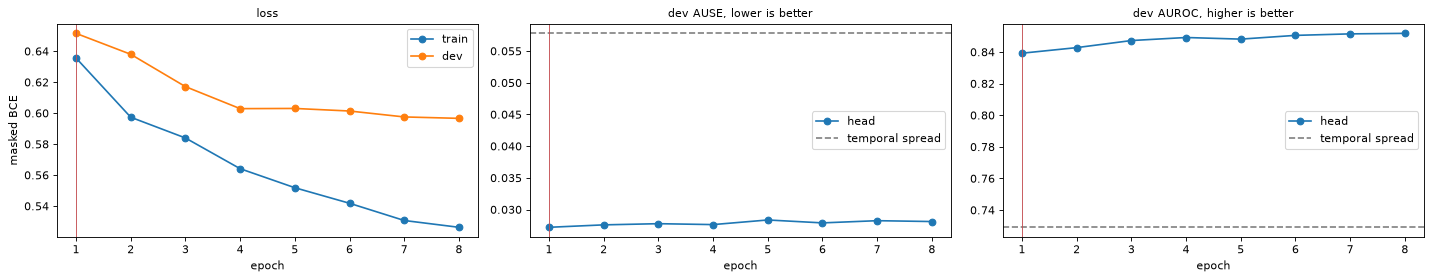

In [11]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
axes[0].plot(epochs, [h["train_loss"] for h in history], "o-", label="train")
axes[0].plot(epochs, [h["dev_loss"] for h in history], "o-", label="dev")
axes[0].set(xlabel="epoch", ylabel="masked BCE", title="loss")
for ax, metric, better in zip(axes[1:], ("ause", "auroc"), ("lower", "higher")):
    ax.plot(epochs, [h[f"dev_{metric}_head"] for h in history], "o-", label="head")
    if f"dev_{metric}_temporal" in history[0]:
        ax.axhline(history[0][f"dev_{metric}_temporal"], color="gray", ls="--", label="temporal spread")
    ax.set(xlabel="epoch", title=f"dev {metric.upper()}, {better} is better")
best_epoch = min(history, key=lambda h: h["dev_ause_head"])["epoch"]
for ax in axes:
    ax.axvline(best_epoch, color="#c44e52", lw=0.8)
    ax.legend()
fig.tight_layout()
print(f"best.pt is epoch {best_epoch}, marked in red")

## 9. Score the Report Split

This section loads `best.pt` and scores it on val, once. The first three lines are all it takes to load a saved head anywhere else.

Each row of the table is a group of val images. `scenes` is the number of scenes behind the row, and a row with fewer than 10 is indicative only. `positive` is the share of labeled cells above `tau`. The head beats the baseline in a row when its AUSE is lower and its AURG and AUROC are higher.

In [12]:
saved = torch.load(RUN_DIR / "best.pt", map_location=device)
head = ConfidenceHead(saved["in_channels"], saved["widths"]).to(device)
head.load_state_dict(saved["head"])

val_scored = evaluate(head, val_loader)
val_images = val_scored["images"]
groups = {"all": val_images}
for field in ("condition", "weather"):
    for value in sorted({im[field] for im in val_images}):
        groups[f"{field} {value}"] = [im for im in val_images if im[field] == value]
val_scores = {name: summarize(images) for name, images in groups.items()}

methods = ["head"] + (["temporal"] if T is not None else [])
headers = ["group", "scenes", "images", "positive"] + [f"{m} {s}" for s in ("AUSE", "AURG", "AUROC") for m in methods]
display(table(headers, [
    (name, s["scenes"] if s["scenes"] >= 10 else f"{s['scenes']} (few)", s["images"], f"{s['positive']:.1%}",
     *[f"{s[f'{k}_{m}']:.4f}" if k != "auroc" else f"{s[f'{k}_{m}']:.3f}" for k in ("ause", "aurg", "auroc") for m in methods])
    for name, s in val_scores.items()]))

(RUN_DIR / "val.json").write_text(json.dumps({"checkpoint_epoch": saved["epoch"], "loss": val_scored["loss"],
                                              "groups": val_scores}, indent=1) + "\n")
(RUN_DIR / "val_images.json").write_text(json.dumps([{k: v for k, v in im.items() if k != "sample"} for im in val_images]) + "\n")
print(f"epoch {saved['epoch']} on {len(val_images)} val images; masked loss {val_scored['loss']:.4f}")

| group | scenes | images | positive | head AUSE | temporal AUSE | head AURG | temporal AURG | head AUROC | temporal AUROC |
|---|---|---|---|---|---|---|---|---|---|
| all | 2 (few) | 486 | 29.4% | 0.0214 | 0.0337 | 0.0634 | 0.0511 | 0.859 | 0.797 |
| condition day | 2 (few) | 486 | 29.4% | 0.0214 | 0.0337 | 0.0634 | 0.0511 | 0.859 | 0.797 |
| weather clear | 2 (few) | 486 | 29.4% | 0.0214 | 0.0337 | 0.0634 | 0.0511 | 0.859 | 0.797 |

epoch 1 on 486 val images; masked loss 0.5698


The plot shows the mean sparsification curves of val. Every curve starts at the mean AbsRel of all labeled cells, where no cell is removed yet. The closer a curve stays to the oracle, the lower its AUSE.

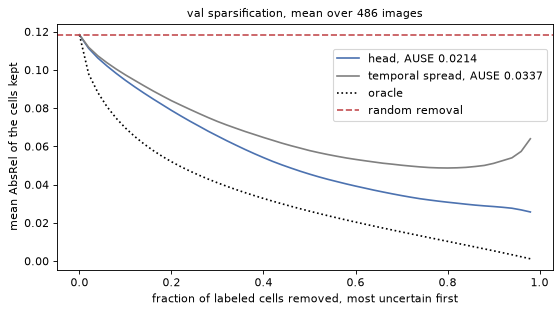

In [13]:
curves = val_scored["curves"]
removed = np.arange(len(curves["oracle"])) / len(curves["oracle"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(removed, curves["head"], label=f"head, AUSE {val_scores['all']['ause_head']:.4f}", color="#4c72b0")
if "temporal" in curves:
    ax.plot(removed, curves["temporal"], label=f"temporal spread, AUSE {val_scores['all']['ause_temporal']:.4f}", color="gray")
ax.plot(removed, curves["oracle"], label="oracle", color="black", ls=":")
ax.axhline(curves["oracle"][0], color="#c44e52", ls="--", label="random removal")
ax.set(xlabel="fraction of labeled cells removed, most uncertain first", ylabel="mean AbsRel of the cells kept",
       title=f"val sparsification, mean over {len(val_images)} images")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.92))
plt.show()

## 10. The Predictions

The figure shows three val images, at the 10th, 50th, and 90th percentile of the head's AUSE: a good, a typical, and a poor image. Each row shows the lidar AbsRel on the labeled cells, the labels, the head's `p_error` on every cell, and the temporal spread. The labels cover scattered cells, while the head fills the whole image.

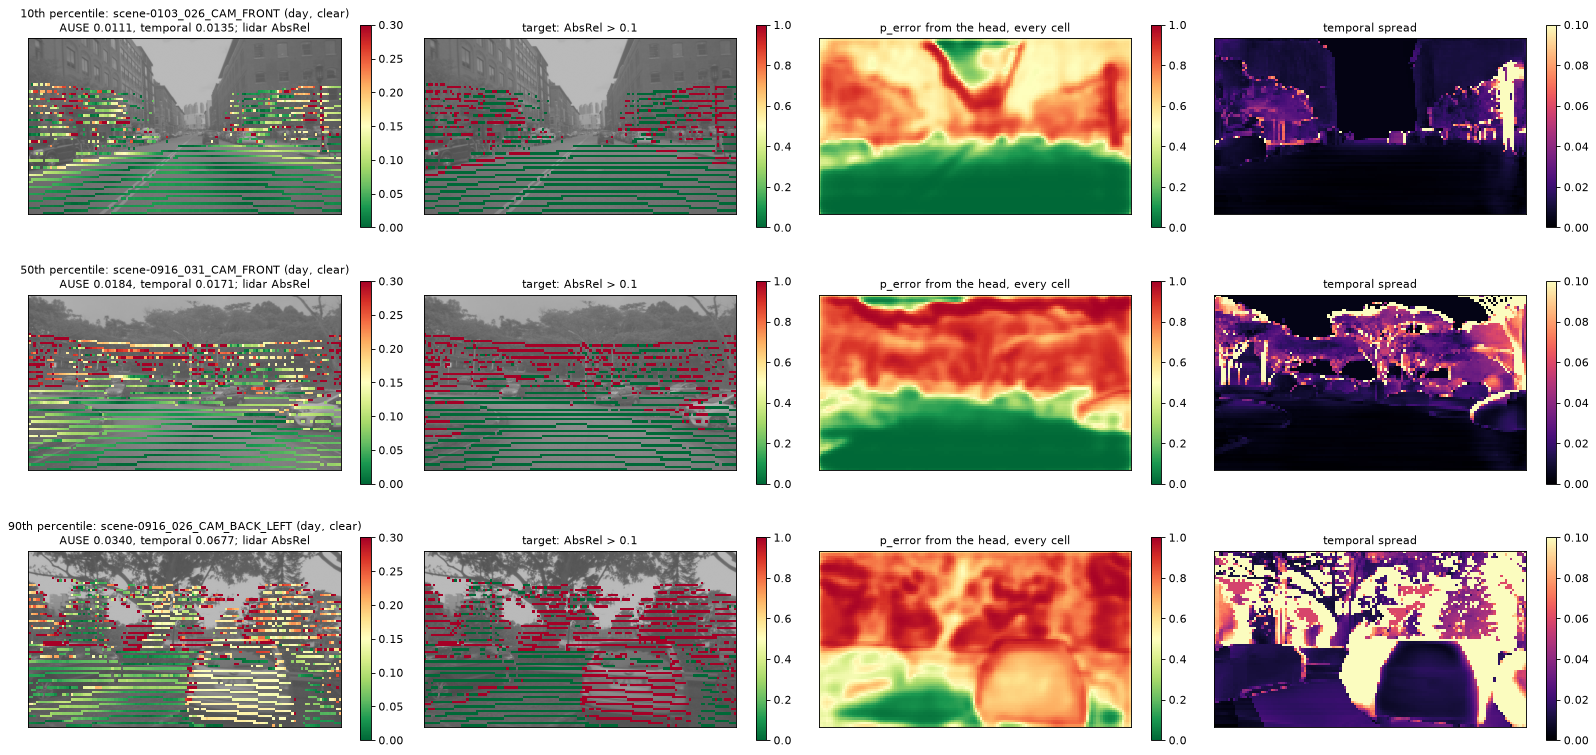

In [14]:
val_position = {r["key"]: i for i, r in enumerate(val_set.rows)}
ranked = sorted(val_images, key=lambda im: im["ause_head"])
picks = [ranked[int(q * (len(ranked) - 1))] for q in (0.1, 0.5, 0.9)]
tau = INPUTS.labels.tau

fig, axes = plt.subplots(len(picks), 4, figsize=(20, 3.3 * len(picks)), squeeze=False)
for row_axes, (q, im) in zip(axes, zip((10, 50, 90), picks)):
    item = val_set[val_position[im["key"]]]
    entry = cache.entry(im["key"])
    rgb = entry.image()
    size = (entry.meta["image"]["width"], entry.meta["image"]["height"])
    with torch.no_grad():
        p_map = torch.sigmoid(head(item["x"][None].to(device)))[0, 0].cpu().numpy()
    labeled = item["mask"][0].numpy() > 0
    panels = [
        (item["abs_rel"][0].numpy(), labeled, dict(cmap="RdYlGn_r", vmin=0, vmax=3 * tau), "lidar AbsRel"),
        (item["target"][0].numpy(), labeled, dict(cmap="RdYlGn_r", vmin=0, vmax=1), f"target: AbsRel > {tau}"),
        (p_map, None, dict(cmap="RdYlGn_r", vmin=0, vmax=1), "p_error from the head, every cell"),
    ]
    if T is not None:
        panels.append((item["x"][T].numpy(), None, dict(cmap="magma", vmin=0, vmax=0.1), "temporal spread"))
    for ax, (values, mask, kw, title) in zip(row_axes, panels):
        imshow = draw_map(ax, values, size, image=rgb if mask is not None else None, mask=mask, **kw)
        ax.set_title(title)
        fig.colorbar(imshow, ax=ax, shrink=0.8)
    row_axes[0].set_title(f"{q}th percentile: {im['key']} ({im['condition']}, {im['weather']})\n"
                          f"AUSE {im['ause_head']:.4f}, temporal {im.get('ause_temporal', float('nan')):.4f}; lidar AbsRel")
    for ax in row_axes[len(panels):]:
        ax.set_axis_off()
fig.tight_layout()

## 11. What `p_error` Means

The class weight changes what `p_error` means. With a weight w on the positive cells, the loss is lowest when the predicted odds p / (1 - p) are w times the true odds. So for w above 1, `p_error` overstates the chance of an error. Its ranking of the cells stays the same, and so do AUSE, AURG, and AUROC. A consumer that needs a probability can undo the weight: p / (p + w (1 - p)).

The left plot bins the val sample cells by `p_error` and compares each bin with the share of its cells that are positive. A calibrated probability lies on the diagonal. Undoing the weight removes only the shift that the weight causes; a gap that remains comes from the head itself, for example from a difference between the train and val scenes. The right plot shows how `p_error` spreads the negative and the positive cells.

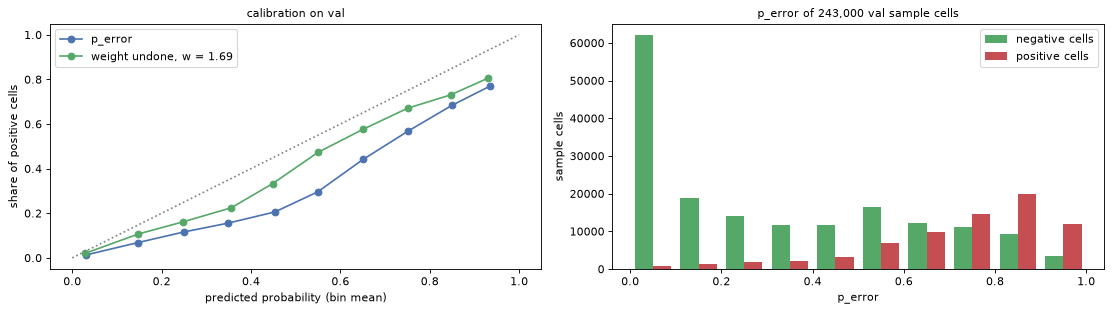

In [15]:
p = np.concatenate([im["sample"]["head"] for im in val_images]).astype(np.float64)
y = np.concatenate([im["sample"]["target"] for im in val_images])
w = saved["pos_weight"]
bins = np.linspace(0, 1, 11)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for values, label, color in ((p, "p_error", "#4c72b0"), (p / (p + w * (1 - p)), f"weight undone, w = {w:.2f}", "#55a868")):
    which = np.clip(np.digitize(values, bins) - 1, 0, len(bins) - 2)
    filled = [b for b in range(len(bins) - 1) if (which == b).any()]
    ax1.plot([values[which == b].mean() for b in filled], [y[which == b].mean() for b in filled], "o-", label=label, color=color)
ax1.plot([0, 1], [0, 1], color="gray", ls=":")
ax1.set(xlabel="predicted probability (bin mean)", ylabel="share of positive cells", title="calibration on val")
ax1.legend()
ax2.hist([p[~y], p[y]], bins=bins, label=["negative cells", "positive cells"], color=["#55a868", "#c44e52"])
ax2.set(xlabel="p_error", ylabel="sample cells", title=f"p_error of {len(p):,} val sample cells")
ax2.legend()
fig.tight_layout()

## 12. What the Run Writes

| File in `RUN_DIR` | What it holds |
|---|---|
| `config.json` | every setting, the dev scenes, the class weight, the cache fingerprint, the git commit |
| `best.pt` | the head of the epoch with the lowest dev AUSE, with its input statistics |
| `last.pt` | the head of the last epoch, with the optimizer and the schedule, to continue the run |
| `history.json` | the losses and the dev scores of each epoch |
| `val.json` | the val scores of `best.pt`, per group |
| `val_images.json` | the val scores of each image |

A checkpoint holds plain tensors, lists, and numbers, so `torch.load` reads it with its default `weights_only=True`.

## Where to Go Next

- **Ablations.** Set `INPUTS` in section 1 to drop a channel group, for example `HeadInputs(radar=False)` or `HeadInputs(features=False, temporal=False)`, and give the run its own `RUN_NAME`. The labels stay the same, so the val scores of two runs compare directly. Without the temporal channel, the notebook has no temporal baseline.
- **Labels.** `HeadInputs(labels=LabelConfig(tau=0.2))` trains on another threshold, and `LabelConfig(align="radar")` makes the labels with the radar fit instead of the lidar fit. Neither needs a new cache.
- **CARC.** [`guides/notebook-on-carc.md`](../guides/notebook-on-carc.md) opens this notebook in JupyterLab on a CARC GPU.
- **The code.** [`src/confhead/head.py`](../src/confhead/head.py) and [`src/confhead/metrics.py`](../src/confhead/metrics.py) hold the head, the loss, and the scores that this notebook uses.